# Dataset Relationship Flow

The Excel workbook contains 10 interconnected datasets.

```text
                         DEPARTMENTS
                            │
                          DeptID
                            │
          ┌─────────────────┼─────────────────┐
          │                 │                 │
          ▼                 ▼                 ▼
      EMPLOYEES          FINANCE          PROJECTS
          │
        EmpID
          │
     ┌────┴─────┐
     ▼          ▼
 ATTENDANCE   SUPPORT_TICKETS
                  │
          ┌───────┴────────┐
          │                │
     CustomerID        ProductID
          │                │
          ▼                ▼
      CUSTOMERS         PRODUCTS
          │                │
          └───────┬────────┘
                  ▼
                ORDERS

DEPARTMENTS
     │
   DeptID
     ▼
MARKETING_CAMPAIGNS



| Relationship                | Key          |
| --------------------------- | ------------ |
| Departments → Employees     | `DeptID`     |
| Departments → Finance       | `DeptID`     |
| Departments → Projects      | `DeptID`     |
| Departments → Marketing     | `DeptID`     |
| Employees → Attendance      | `EmpID`      |
| Employees → Support Tickets | `EmpID`      |
| Customers → Orders          | `CustomerID` |
| Products → Orders           | `ProductID`  |
| Customers → Support Tickets | `CustomerID` |
| Products → Support Tickets  | `ProductID`  |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "Organization_Business_Data.xlsx"

sheets = pd.ExcelFile(file_path).sheet_names
print(sheets)

['Departments', 'Employees', 'Products', 'Customers', 'Orders', 'Marketing_Campaigns', 'Finance_Monthly', 'Attendance_Monthly', 'Support_Tickets', 'Projects']


In [2]:
departments = pd.read_excel(file_path, sheet_name="Departments")
employees = pd.read_excel(file_path, sheet_name="Employees")
products = pd.read_excel(file_path, sheet_name="Products")
customers = pd.read_excel(file_path, sheet_name="Customers")
orders = pd.read_excel(file_path, sheet_name="Orders")
marketing = pd.read_excel(file_path, sheet_name="Marketing_Campaigns")
finance = pd.read_excel(file_path, sheet_name="Finance_Monthly")
attendance = pd.read_excel(file_path, sheet_name="Attendance_Monthly")
support = pd.read_excel(file_path, sheet_name="Support_Tickets")
projects = pd.read_excel(file_path, sheet_name="Projects")

print("All datasets loaded successfully.")

All datasets loaded successfully.


##  Data Inspection

The structure of each dataset is inspected using shape, columns, head,
and statistical summary.

In [3]:
datasets = {
    "Departments": departments,
    "Employees": employees,
    "Products": products,
    "Customers": customers,
    "Orders": orders,
    "Marketing": marketing,
    "Finance": finance,
    "Attendance": attendance,
    "Support": support,
    "Projects": projects
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

display(orders.head())
display(orders.describe())

Departments: (10, 5)
Employees: (226, 18)
Products: (22, 8)
Customers: (610, 8)
Orders: (6025, 13)
Marketing: (40, 10)
Finance: (430, 7)
Attendance: (7090, 9)
Support: (2200, 11)
Projects: (25, 10)


,OrderID,OrderDate,CustomerID,ProductID,EmployeeID,Quantity,UnitPrice_INR,Discount_Pct,TotalAmount_INR,Region,PaymentMethod,OrderStatus,DeliveryDate
0,O02799,2022-04-29,C0255,P009,E0174,1,19960.0,0,19960.0,West,Credit Card,Completed,2022-05-08
1,O00043,2025-04-12,C0017,P021,E0004,2,11090.0,0,22180.0,South,Bank Transfer,Completed,2025-04-21
2,O03169,2024-07-22,C0447,P022,E0029,2,41220.0,20,65952.0,East,UPI,Completed,2024-07-26
3,O02114,2024-09-28,C0050,P009,E0043,1,19960.0,5,18962.0,West,Bank Transfer,Cancelled,NaN
4,O02646,2024-08-12,C0021,P012,E0167,4,37190.0,5,141322.0,Central,Net Banking,Completed,2024-08-21


,Quantity,UnitPrice_INR,Discount_Pct
count,6025.000000,6025.000000,6025.000000
mean,2.310041,28228.147718,5.291286
std,1.985457,19971.184800,6.056449
min,-5.000000,3080.000000,0.000000
25%,1.000000,11090.000000,0.000000
50%,2.000000,23800.000000,5.000000
75%,3.000000,44810.000000,10.000000
max,10.000000,74070.000000,20.000000


## Data Quality Check

Missing values, duplicate records, and categorical distributions are
checked before analysis.

In [5]:
for name, df in datasets.items():
    print(name, "Missing:", df.isnull().sum().sum(),
          "Duplicates:", df.duplicated().sum())

print("\nOrder Status:")
print(orders["OrderStatus"].value_counts())

print("\nCustomer Segments:")
print(customers["Segment"].value_counts())

Departments Missing: 0 Duplicates: 0
Employees Missing: 259 Duplicates: 6
Products Missing: 14 Duplicates: 0
Customers Missing: 185 Duplicates: 10
Orders Missing: 1553 Duplicates: 17
Marketing Missing: 0 Duplicates: 0
Finance Missing: 34 Duplicates: 0
Attendance Missing: 284 Duplicates: 30
Support Missing: 870 Duplicates: 0
Projects Missing: 0 Duplicates: 0

Order Status:
OrderStatus
Completed    3570
completed    1210
Pending       322
Returned      305
Cancelled     300
cancelled     111
pending       107
returned      100
Name: count, dtype: int64

Customer Segments:
Segment
SMB           205
Individual     99
Startup        92
Enterprise     76
smb            61
individual     33
startup        24
enterprise     20
Name: count, dtype: int64


## Data Cleaning

Duplicate records are removed, text values are standardized, and date
and numerical columns are converted into appropriate formats.

In [10]:
for df in datasets.values():
    df.drop_duplicates(inplace=True)

orders["OrderStatus"] = orders["OrderStatus"].astype(str).str.strip().str.title()
employees["EmploymentStatus"] = employees["EmploymentStatus"].astype(str).str.strip().str.title()
projects["Status"] = projects["Status"].astype(str).str.strip().str.title()

orders["OrderDate"] = pd.to_datetime(orders["OrderDate"], errors="coerce")
employees["HireDate"] = pd.to_datetime(employees["HireDate"], errors="coerce")
customers["JoinDate"] = pd.to_datetime(customers["JoinDate"], errors="coerce")
finance["MonthYear"] = pd.to_datetime(finance["MonthYear"], errors="coerce")

## Selecting, Filtering and Sorting

Pandas allows us to select required columns, filter records based on
conditions, and sort data to identify important records.

In [14]:
orders["TotalAmount_INR"] = (
    orders["TotalAmount_INR"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("₹", "", regex=False)
    .str.strip()
)

orders["TotalAmount_INR"] = pd.to_numeric(
    orders["TotalAmount_INR"],
    errors="coerce"
)

display(
    orders[["OrderID", "CustomerID", "ProductID", "TotalAmount_INR"]].head()
)

median_value = orders["TotalAmount_INR"].median()

high_value_orders = orders[
    orders["TotalAmount_INR"] > median_value
]

display(high_value_orders.head())

top_orders = orders.sort_values(
    by="TotalAmount_INR",
    ascending=False
).head(10)

display(top_orders)

,OrderID,CustomerID,ProductID,TotalAmount_INR
0,O02799,C0255,P009,19960.0
1,O00043,C0017,P021,22180.0
2,O03169,C0447,P022,65952.0
3,O02114,C0050,P009,18962.0
4,O02646,C0021,P012,141322.0


,OrderID,OrderDate,CustomerID,ProductID,EmployeeID,Quantity,UnitPrice_INR,Discount_Pct,TotalAmount_INR,Region,PaymentMethod,OrderStatus,DeliveryDate
2,O03169,2024-07-22,C0447,P022,E0029,2,41220.0,20,65952.0,East,UPI,Completed,2024-07-26
4,O02646,2024-08-12,C0021,P012,E0167,4,37190.0,5,141322.0,Central,Net Banking,Completed,2024-08-21
5,O02296,2026-01-11,C0508,P016,E0103,2,23800.0,5,45220.0,North,UPI,Completed,2026-01-17
6,O01426,2025-06-11,C0256,P015,E0169,3,74070.0,0,222210.0,North,Credit Card,Completed,2025-06-13
9,O01884,NaT,C0548,P001,E0151,3,44810.0,10,120987.0,West,Credit Card,Returned,NaN


,OrderID,OrderDate,CustomerID,ProductID,EmployeeID,Quantity,UnitPrice_INR,Discount_Pct,TotalAmount_INR,Region,PaymentMethod,OrderStatus,DeliveryDate
443,O02708,2025-10-25,C0122,P001,E0217,2,44810.0,10,8065800.0,West,Net Banking,Completed,2025-10-31
2155,O00399,2019-08-08,C0022,P001,E0060,2,44810.0,15,7617700.0,South,Cheque,Completed,2019-08-09
5413,O05308,2024-10-31,C0114,P012,E0134,2,37190.0,5,7066100.0,East,UPI,Completed,2024-11-05
908,O02806,2018-05-01,C0473,P001,E0142,1,44810.0,5,4256950.0,Central,Credit Card,Completed,2018-05-11
3635,O03207,NaT,C0177,P021,E0167,1,11090.0,5,1053550.0,West,Credit Card,Completed,2023-04-27
306,O05480,2024-11-16,C0027,P015,E0174,10,74070.0,0,740700.0,South,Credit Card,Completed,2024-11-21
5928,O03301,2024-04-26,C0436,P015,E0090,10,74070.0,0,740700.0,Central,Net Banking,Completed,2024-05-05
3976,O02457,2021-09-20,C0088,P015,E0084,10,74070.0,0,740700.0,Central,Cheque,Completed,2021-09-23
1053,O04204,2025-02-17,C0545,P015,E0041,10,74070.0,5,703665.0,Central,NaN,Completed,2025-02-22
2207,O06000,NaT,C0582,P015,E0115,10,74070.0,10,666630.0,West,Credit Card,Completed,2025-09-03


## Grouping and Aggregation

In [16]:
sales_region = orders.groupby("Region")["TotalAmount_INR"].sum().sort_values(ascending=False)

quantity_region = orders.groupby("Region")["Quantity"].sum().sort_values(ascending=False)

orders_payment = orders["PaymentMethod"].value_counts()

print("Revenue by Region")
display(sales_region)

print("Quantity Sold by Region")
display(quantity_region)

print("Orders by Payment Method")
display(orders_payment)

Revenue by Region


Region
West       84144583.0
East       82757839.0
South      81906773.0
Central    74373906.0
North      74255829.0
Name: TotalAmount_INR, dtype: float64

Quantity Sold by Region


Region
West       2833
North      2808
East       2782
South      2762
Central    2666
Name: Quantity, dtype: int64

Orders by Payment Method


PaymentMethod
Net Banking      1188
Cheque           1166
Credit Card      1137
Bank Transfer    1135
UPI              1068
Name: count, dtype: int64

##  Combining Related Datasets

In [17]:
orders_analysis = orders.merge(
    customers[["CustomerID", "CustomerName", "Segment"]],
    on="CustomerID",
    how="left"
)

orders_analysis = orders_analysis.merge(
    products[["ProductID", "ProductName", "Category"]],
    on="ProductID",
    how="left"
)

print("Merged Data Shape:", orders_analysis.shape)

display(orders_analysis.head())

Merged Data Shape: (6000, 17)


,OrderID,OrderDate,CustomerID,ProductID,EmployeeID,Quantity,UnitPrice_INR,Discount_Pct,TotalAmount_INR,Region,PaymentMethod,OrderStatus,DeliveryDate,CustomerName,Segment,ProductName,Category
0,O02799,2022-04-29,C0255,P009,E0174,1,19960.0,0,19960.0,West,Credit Card,Completed,2022-05-08,Uma Gupta,Individual,Nimbus Router X1,Hardware
1,O00043,2025-04-12,C0017,P021,E0004,2,11090.0,0,22180.0,South,Bank Transfer,Completed,2025-04-21,Horizon Textiles,smb,Priority Onboarding,Add-ons
2,O03169,2024-07-22,C0447,P022,E0029,2,41220.0,20,65952.0,East,UPI,Completed,2024-07-26,Ananya Singh,Individual,Custom Integration Pack,Add-ons
3,O02114,2024-09-28,C0050,P009,E0043,1,19960.0,5,18962.0,West,Bank Transfer,Cancelled,NaN,Beta Enterprises,SMB,Nimbus Router X1,Hardware
4,O02646,2024-08-12,C0021,P012,E0167,4,37190.0,5,141322.0,Central,Net Banking,Completed,2024-08-21,Metro Motors,SMB,Nimbus Smart Switch,Hardware


## Key Performance Indicators

In [18]:
total_revenue = orders["TotalAmount_INR"].sum()

total_orders = orders["OrderID"].nunique()

average_order_value = total_revenue / total_orders

total_customers = customers["CustomerID"].nunique()

active_employees = (
    employees["EmploymentStatus"].eq("Active").sum()
)

total_profit = finance["Profit_INR"].sum()

kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Customers",
        "Active Employees",
        "Total Profit"
    ],
    "Value": [
        total_revenue,
        total_orders,
        average_order_value,
        total_customers,
        active_employees,
        total_profit
    ]
})

display(kpis)

,KPI,Value
0,Total Revenue,3.974389e+08
1,Total Orders,6.000000e+03
2,Average Order Value,6.623982e+04
3,Total Customers,6.000000e+02
4,Active Employees,1.830000e+02
5,Total Profit,3.892687e+06


In [19]:
product_sales = (
    orders_analysis.groupby("ProductName")["TotalAmount_INR"]
    .sum()
    .sort_values(ascending=False)
)

customer_segments = customers["Segment"].value_counts()

finance_summary = finance[
    ["Revenue_INR", "Expenses_INR", "Profit_INR"]
].sum()

marketing_summary = marketing.groupby("Channel").agg(
    Budget=("Budget_INR", "sum"),
    Leads=("LeadsGenerated", "sum")
)

support_summary = support["IssueType"].value_counts()

project_summary = projects["Status"].value_counts()

print("Top Products")
display(product_sales.head(10))

print("Customer Segments")
display(customer_segments)

print("Finance Summary")
display(finance_summary)

print("Marketing Summary")
display(marketing_summary)

print("Support Issues")
display(support_summary)

print("Project Status")
display(project_summary)

Top Products


ProductName
NimbusCRM Pro              48426167.0
NimbusExpense Tracker      42956896.5
Nimbus NAS 4-Bay           36803724.0
NimbusAnalytics            35241186.0
Nimbus Smart Switch        27805103.5
Custom Integration Pack    26294238.0
NimbusHR Cloud             24463992.0
Enterprise SLA Plan        24131298.0
NimbusSecure Endpoint      17634254.5
NimbusERP Suite            17604162.0
Name: TotalAmount_INR, dtype: float64

Customer Segments


Segment
SMB           199
Individual     97
Startup        92
Enterprise     76
smb            60
individual     33
startup        24
enterprise     19
Name: count, dtype: int64

Finance Summary


...

,Budget,Leads
Channel,,
EMAIL,1806048,3066
Email,11033882,14569
Events,10074942,15546
GOOGLE ADS,1225191,1514
Google Ads,5109184,7009
INFLUENCER,235150,553
Influencer,7367475,9984
PRINT,1006180,2502
Print,3992835,4969


Support Issues


IssueType
Hardware Malfunction    205
Security Concern        199
Installation Help       197
Integration Issue       189
Refund Request          187
Bug Report              184
Performance Issue       183
Data Migration          177
Login Issue             175
Account Setup           171
Feature Request         169
Billing Query           164
Name: count, dtype: int64

Project Status


Status
Completed      11
Delayed         7
In Progress     5
On Hold         1
Planned         1
Name: count, dtype: int64

## Data Visualization

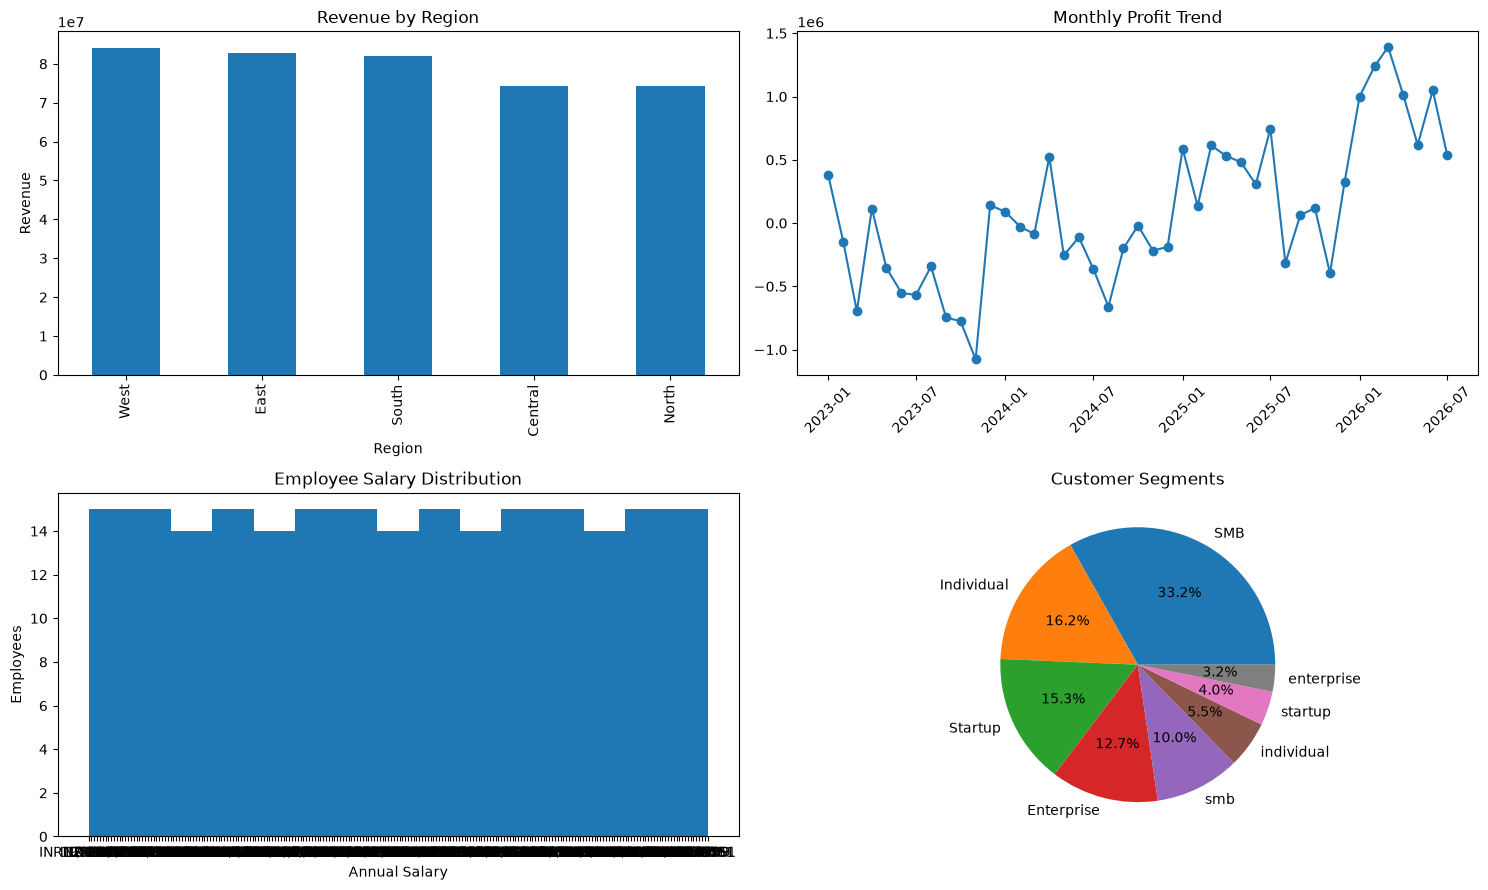

In [20]:
monthly_profit = (
    finance.groupby("MonthYear")["Profit_INR"]
    .sum()
    .sort_index()
)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sales_region.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Revenue by Region")
axes[0, 0].set_xlabel("Region")
axes[0, 0].set_ylabel("Revenue")

axes[0, 1].plot(
    monthly_profit.index,
    monthly_profit.values,
    marker="o"
)
axes[0, 1].set_title("Monthly Profit Trend")
axes[0, 1].tick_params(axis="x", rotation=45)

axes[1, 0].hist(
    employees["AnnualSalary_INR"].dropna(),
    bins=15
)
axes[1, 0].set_title("Employee Salary Distribution")
axes[1, 0].set_xlabel("Annual Salary")
axes[1, 0].set_ylabel("Employees")

axes[1, 1].pie(
    customer_segments.values,
    labels=customer_segments.index,
    autopct="%1.1f%%"
)
axes[1, 1].set_title("Customer Segments")

plt.tight_layout()
plt.show()

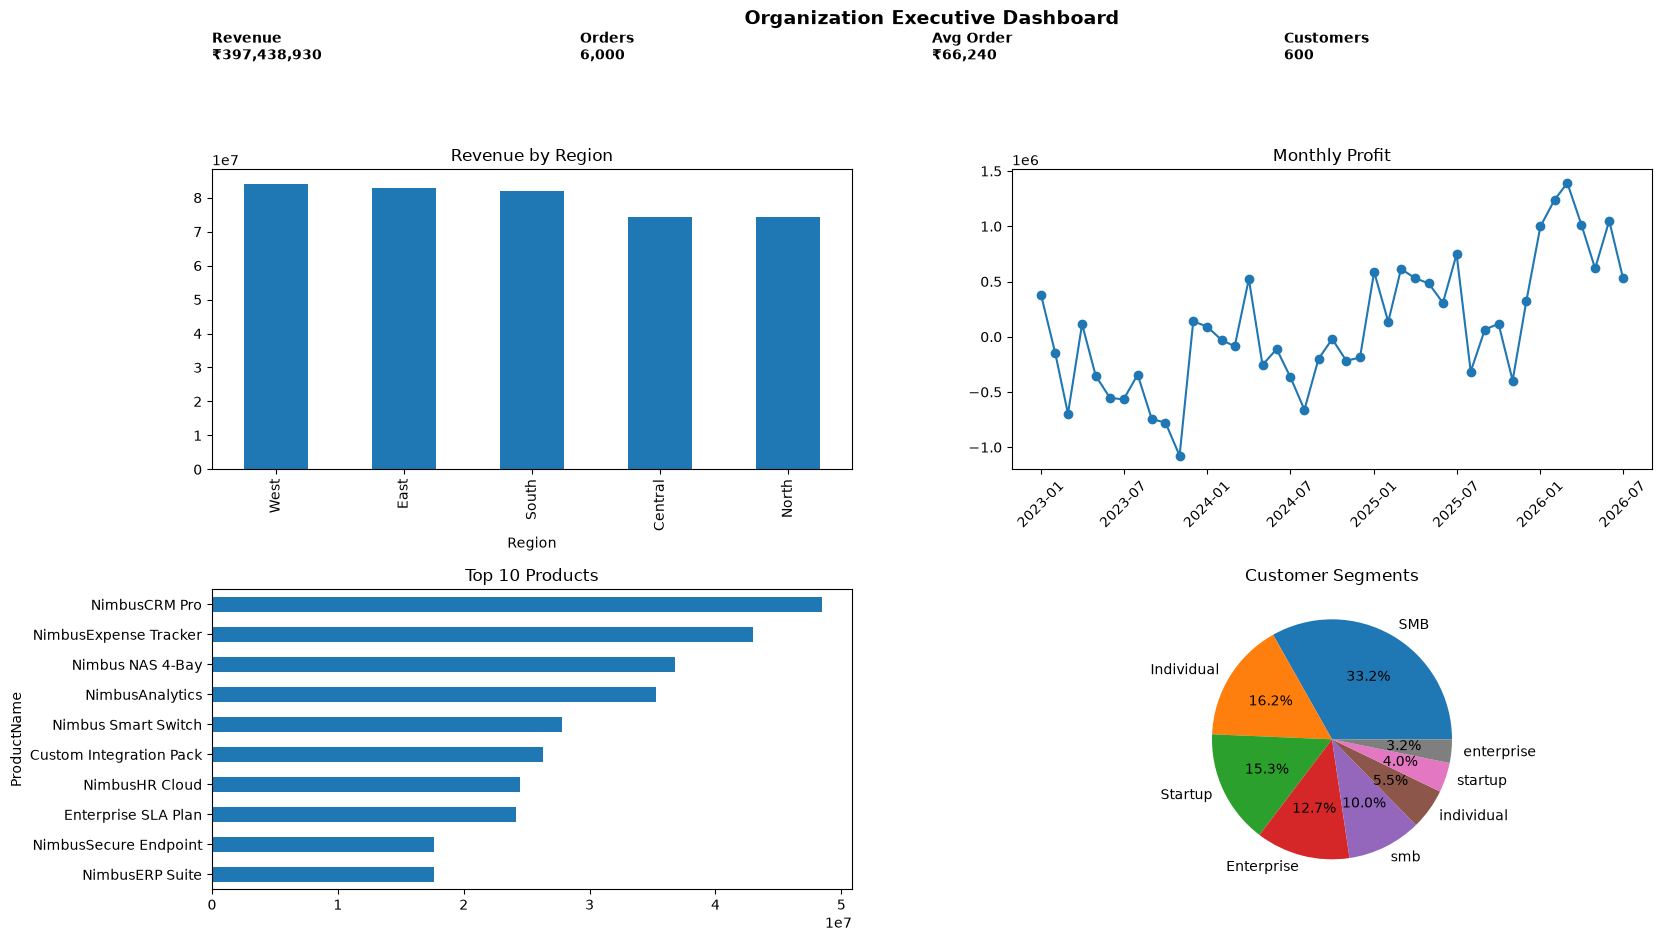

In [24]:
fig = plt.figure(figsize=(16, 10))

fig.text(
    0.05, 0.93,
    f"Revenue\n₹{total_revenue:,.0f}",
    fontsize=10,
    fontweight="bold"
)

fig.text(
    0.28, 0.93,
    f"Orders\n{total_orders:,}",
    fontsize=10,
    fontweight="bold"
)

fig.text(
    0.50, 0.93,
    f"Avg Order\n₹{average_order_value:,.0f}",
    fontsize=10,
    fontweight="bold"
)

fig.text(
    0.72, 0.93,
    f"Customers\n{total_customers:,}",
    fontsize=10,
    fontweight="bold"
)

ax1 = fig.add_axes([0.05, 0.52, 0.40, 0.30])
sales_region.plot(kind="bar", ax=ax1)
ax1.set_title("Revenue by Region")

ax2 = fig.add_axes([0.55, 0.52, 0.40, 0.30])
ax2.plot(
    monthly_profit.index,
    monthly_profit.values,
    marker="o"
)
ax2.set_title("Monthly Profit")
ax2.tick_params(axis="x", rotation=45)

ax3 = fig.add_axes([0.05, 0.10, 0.40, 0.30])
product_sales.head(10).sort_values().plot(
    kind="barh",
    ax=ax3
)
ax3.set_title("Top 10 Products")

ax4 = fig.add_axes([0.55, 0.10, 0.40, 0.30])
ax4.pie(
    customer_segments.values,
    labels=customer_segments.index,
    autopct="%1.1f%%"
)
ax4.set_title("Customer Segments")

fig.suptitle(
    "Organization Executive Dashboard",
    fontsize=14,
    fontweight="bold"
)

plt.show()